# Diabetes Prediction using Machine Learning

**Goal:** build an end-to-end classification pipeline that predicts whether a patient is likely to have diabetes (`Outcome = 1`) from routine medical measurements.

**Workflow:**
1. Data Preparation: load, explore, clean, split, scale
2. Model Building: Logistic Regression and why it fits
3. Model Training & Evaluation: training/test accuracy, precision, recall, F1, confusion matrix
4. Model Performance Analysis: interpretation, feature importance, insights

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay)

RANDOM_STATE = 42
IMG_DIR = Path("images")
IMG_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

---
# Part 1: Data Preparation

## 1.1 Load the dataset

In [2]:
df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 1.2 Explore the dataset
### a. Shape

In [3]:
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

Rows: 768, Columns: 9


### b. Column names and c. Data types

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


### d. Missing values

In [5]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

There are **no empty (NaN) cells**. However, several columns contain **zeros that are medically impossible**: a living patient cannot have a glucose level, blood pressure, skin thickness, insulin level or BMI of 0. These zeros are placeholders for **missing measurements** and need to be treated as missing values.

(`Pregnancies = 0` is valid, so it is left as is.)

In [6]:
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

hidden_missing = pd.DataFrame({
    "zero_count": (df[zero_as_missing] == 0).sum(),
    "zero_pct": ((df[zero_as_missing] == 0).mean() * 100).round(1),
})
hidden_missing

,zero_count,zero_pct
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4


### e. Basic statistical summary

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845,3.370,0.000,1.000,3.000,6.000,17.00
Glucose,768.0,120.895,31.973,0.000,99.000,117.000,140.250,199.00
BloodPressure,768.0,69.105,19.356,0.000,62.000,72.000,80.000,122.00
SkinThickness,768.0,20.536,15.952,0.000,0.000,23.000,32.000,99.00
Insulin,768.0,79.799,115.244,0.000,0.000,30.500,127.250,846.00
BMI,768.0,31.993,7.884,0.000,27.300,32.000,36.600,67.10
DiabetesPedigreeFunction,768.0,0.472,0.331,0.078,0.244,0.372,0.626,2.42
Age,768.0,33.241,11.760,21.000,24.000,29.000,41.000,81.00
Outcome,768.0,0.349,0.477,0.000,0.000,0.000,1.000,1.00


Notice that the `min` of Glucose, BloodPressure, SkinThickness, Insulin and BMI is 0, which confirms the hidden missing values above. Insulin has a very large spread (max 846), and Age and Pregnancies are right-skewed.

### Target variable distribution

Outcome
No Diabetes (0)    500
Diabetes (1)       268
Name: count, dtype: int64

Positive class share: 34.9%


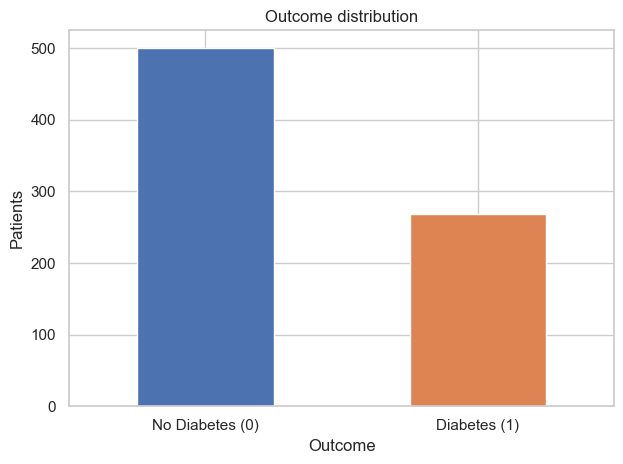

In [8]:
counts = df["Outcome"].value_counts().sort_index()
print(counts.rename({0: "No Diabetes (0)", 1: "Diabetes (1)"}))
print(f"\nPositive class share: {counts[1] / counts.sum():.1%}")

ax = counts.plot(kind="bar", color=["#4C72B0", "#DD8452"])
ax.set_xticklabels(["No Diabetes (0)", "Diabetes (1)"], rotation=0)
ax.set_ylabel("Patients")
ax.set_title("Outcome distribution")
plt.tight_layout(); plt.savefig(IMG_DIR / "outcome_distribution.png", dpi=120); plt.show()

The dataset is **moderately imbalanced** (~65% non-diabetic vs ~35% diabetic). A model that always predicts "No Diabetes" would already score ~65% accuracy, so we must look beyond accuracy (precision, recall, F1) and use a **stratified** split.

### Feature distributions by outcome

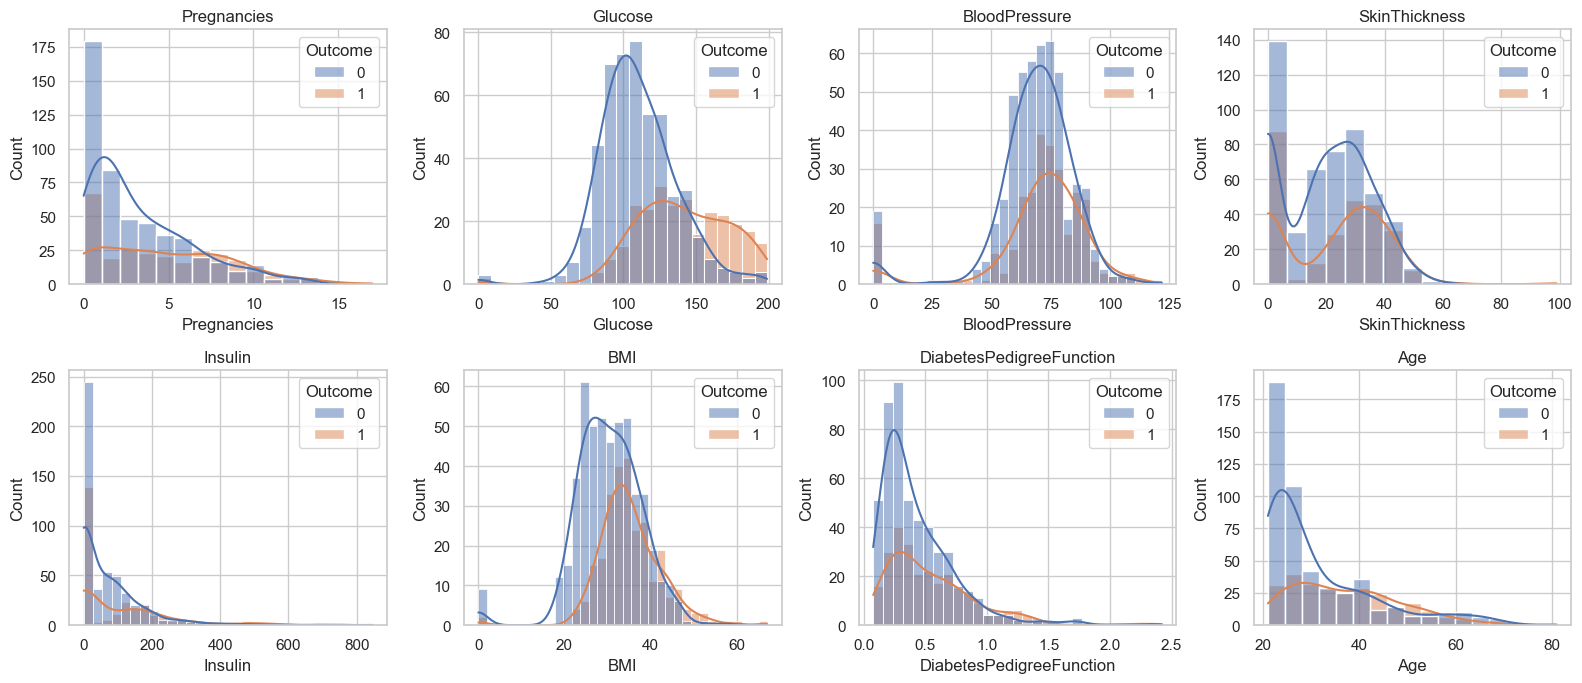

In [9]:
features = df.columns.drop("Outcome")
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(data=df, x=col, hue="Outcome", kde=True, ax=ax, palette=["#4C72B0", "#DD8452"])
    ax.set_title(col)
plt.tight_layout(); plt.savefig(IMG_DIR / "feature_distributions.png", dpi=120); plt.show()

### Correlation heatmap

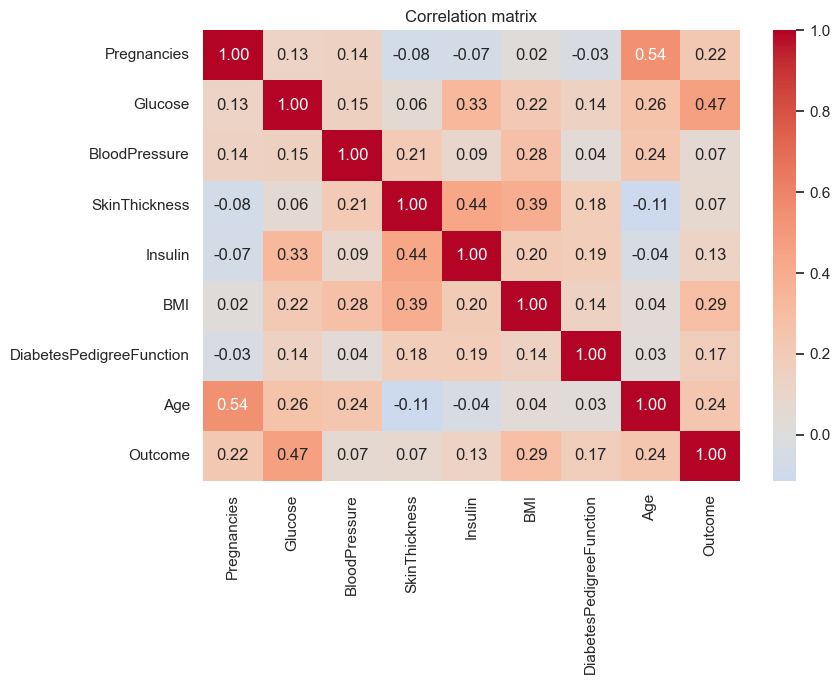

Glucose                     0.467
BMI                         0.293
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
Insulin                     0.131
SkinThickness               0.075
BloodPressure               0.065
Name: Outcome, dtype: float64

In [10]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.tight_layout(); plt.savefig(IMG_DIR / "correlation_heatmap.png", dpi=120); plt.show()

df.corr()["Outcome"].drop("Outcome").sort_values(ascending=False)

**EDA observations**
- **Glucose** has the strongest correlation with Outcome (~0.47), followed by **BMI**, **Age** and **Pregnancies**.
- Diabetic patients show visibly higher glucose and BMI distributions.
- No pair of features is so strongly correlated (all < 0.6) that it would cause serious multicollinearity, so all features are kept.

### Dataset exploration summary

| Item | Finding |
|---|---|
| Rows × Columns | 768 × 9 |
| Feature types | All numeric (int64 / float64); no categorical variables |
| Explicit missing (NaN) | None |
| Hidden missing (zeros) | Glucose, BloodPressure, SkinThickness, Insulin, BMI (Insulin ~49%, SkinThickness ~30%) |
| Target balance | 500 non-diabetic / 268 diabetic (~35% positive) |

## 1.3 Separate features (X) and target (y)

| Role | Columns |
|---|---|
| **Features (X)** | Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, Age |
| **Target (y)** | Outcome (0 = No Diabetes, 1 = Diabetes) |

First, the impossible zeros are replaced with `NaN` so they are treated as missing values. They are *imputed later*, after the split, to avoid data leakage.

In [11]:
data = df.copy()
data[zero_as_missing] = data[zero_as_missing].replace(0, np.nan)

X = data.drop(columns="Outcome")
y = data["Outcome"]
print("X shape:", X.shape, "| y shape:", y.shape)
X.isnull().sum()

X shape: (768, 8) | y shape: (768,)


Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
dtype: int64

## 1.4 Train-Test Split
80% training / 20% testing, **stratified** on the target so both sets keep the same diabetic/non-diabetic ratio.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Training set: {X_train.shape[0]} rows ({X_train.shape[0] / len(X):.0%})")
print(f"Testing set : {X_test.shape[0]} rows ({X_test.shape[0] / len(X):.0%})")
print(f"\nPositive share: train = {y_train.mean():.1%}, test = {y_test.mean():.1%}")

Training set: 614 rows (80%)
Testing set : 154 rows (20%)

Positive share: train = 34.9%, test = 35.1%


## 1.5 Preprocessing

| Step | Applied? | How / Why |
|---|---|---|
| **a. Handle missing values** | Yes | Impossible zeros → NaN → filled with the **median** of the *training* set. Median is robust to the skew/outliers seen in Insulin and SkinThickness. |
| **b. Encode categorical variables** | Not needed | All features are already numeric. |
| **c. Scale numerical features** | Yes | `StandardScaler` (mean 0, std 1). Features have very different ranges (DiabetesPedigreeFunction ≈ 0–2.4 vs Insulin ≈ 14–846). Logistic Regression uses regularisation and gradient-based optimisation, which both work best on comparable scales. |

Both the imputer and the scaler are **fitted on the training data only** and then applied to the test data, so no information from the test set leaks into training.

In [13]:
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_prep = scaler.fit_transform(imputer.fit_transform(X_train))
X_test_prep = scaler.transform(imputer.transform(X_test))

print("Medians learned from training data:")
print(pd.Series(imputer.statistics_, index=X.columns).round(2))

pd.DataFrame(X_train_prep, columns=X.columns).describe().loc[["mean", "std"]].round(2)

Medians learned from training data:
Pregnancies                   3.00
Glucose                     117.00
BloodPressure                72.00
SkinThickness                29.00
Insulin                     125.00
BMI                          32.40
DiabetesPedigreeFunction      0.38
Age                          29.00
dtype: float64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
mean,-0.0,-0.0,0.0,-0.0,-0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


After preprocessing, the training features have mean ≈ 0 and std ≈ 1, with no missing values left.

---
# Part 2: Machine Learning Model Building

## 2.1 Selected algorithm: Logistic Regression

**Why Logistic Regression is suitable for this problem**
- **Binary target:** Outcome is 0/1, and Logistic Regression directly models the *probability* that a patient is diabetic via the sigmoid function.
- **Interpretable:** each coefficient shows how much a feature raises or lowers the log-odds of diabetes. This matters in healthcare, where clinicians need to understand *why* a prediction was made.
- **Probability outputs:** the decision threshold can be tuned. For example, it can be lowered to catch more diabetic patients when missing a case is costly.
- **Works well on small, tabular data:** with 768 rows and 8 numeric features, a simple linear model is less likely to overfit than complex models.
- **Strong, standard baseline:** fast to train and a widely used reference model for medical risk scoring.

In [14]:
model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
model

LogisticRegression(max_iter=1000, random_state=42)

---
# Part 3: Model Training & Evaluation

## 3.1 Fit the model on the training set

In [15]:
model.fit(X_train_prep, y_train)

print("Model trained.")
print("Intercept:", model.intercept_.round(3))
pd.Series(model.coef_[0], index=X.columns, name="coefficient").round(3)

Model trained.
Intercept: [-0.872]


Pregnancies                 0.377
Glucose                     1.183
BloodPressure              -0.044
SkinThickness               0.028
Insulin                    -0.066
BMI                         0.689
DiabetesPedigreeFunction    0.233
Age                         0.148
Name: coefficient, dtype: float64

## 3.2 Predictions and accuracy on the training set

In [16]:
y_train_pred = model.predict(X_train_prep)
train_acc = accuracy_score(y_train, y_train_pred)
print(f"Training accuracy: {train_acc:.4f}")

Training accuracy: 0.7964


## 3.3 Predictions on the test set: accuracy, precision, recall, F1

In [17]:
y_test_pred = model.predict(X_test_prep)
y_test_proba = model.predict_proba(X_test_prep)[:, 1]

test_acc = accuracy_score(y_test, y_test_pred)
print(f"Test accuracy : {test_acc:.4f}")
print(f"Precision     : {precision_score(y_test, y_test_pred):.4f}")
print(f"Recall        : {recall_score(y_test, y_test_pred):.4f}")
print(f"F1-score      : {f1_score(y_test, y_test_pred):.4f}")
print(f"ROC-AUC       : {roc_auc_score(y_test, y_test_proba):.4f}\n")

print(classification_report(y_test, y_test_pred, target_names=["No Diabetes", "Diabetes"]))

Test accuracy : 0.7078
Precision     : 0.6000
Recall        : 0.5000
F1-score      : 0.5455
ROC-AUC       : 0.8130

              precision    recall  f1-score   support

 No Diabetes       0.75      0.82      0.78       100
    Diabetes       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



## 3.4 Confusion matrix

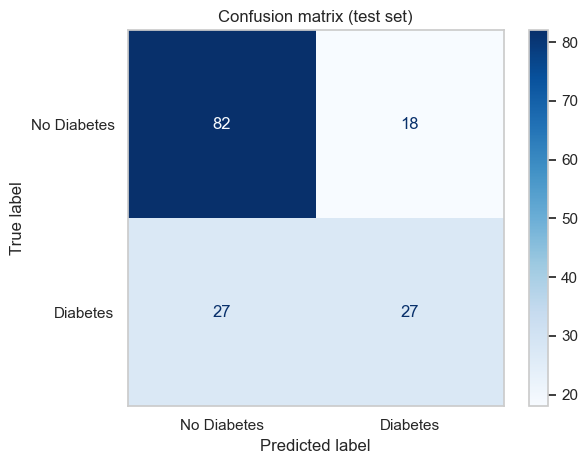

True Negatives : 82  (healthy, correctly cleared)
False Positives: 18  (healthy, wrongly flagged)
False Negatives: 27  (diabetic, MISSED)
True Positives : 27  (diabetic, correctly detected)


In [18]:
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=["No Diabetes", "Diabetes"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix (test set)")
plt.grid(False)
plt.tight_layout(); plt.savefig(IMG_DIR / "confusion_matrix.png", dpi=120); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives : {tn}  (healthy, correctly cleared)")
print(f"False Positives: {fp}  (healthy, wrongly flagged)")
print(f"False Negatives: {fn}  (diabetic, MISSED)")
print(f"True Positives : {tp}  (diabetic, correctly detected)")

## 3.5 Training vs testing performance

In [19]:
def metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
    }

comparison = pd.DataFrame({
    "Train": metrics(y_train, y_train_pred),
    "Test": metrics(y_test, y_test_pred),
})
comparison["Gap (Train - Test)"] = comparison["Train"] - comparison["Test"]
comparison.round(4)

,Train,Test,Gap (Train - Test)
Accuracy,0.796,0.708,0.089
Precision,0.770,0.600,0.170
Recall,0.594,0.500,0.093
F1-score,0.670,0.545,0.125


In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
cv_scores = cross_val_score(cv_pipeline, X_train, y_train, cv=cv, scoring="accuracy")
print("5-fold CV accuracy on training data:", cv_scores.round(3))
print(f"Mean = {cv_scores.mean():.4f}  ± {cv_scores.std():.4f}")

5-fold CV accuracy on training data: [0.789 0.789 0.821 0.78  0.762]
Mean = 0.7882  ± 0.0191


**Interpretation**
- **Training accuracy ≈ 79.6%, test accuracy ≈ 70.8%**, a gap of about 9 points.
- The **5-fold cross-validation accuracy (≈ 78.8% ± 1.9%)** matches the training score closely. A linear model with only 9 parameters has little capacity to memorise 614 rows, so the gap is mostly explained by **this particular 154-row test split being harder than average** (small test sets have high variance: one patient = 0.65 percentage points), not by severe overfitting. The realistic expected accuracy is roughly **71–79%**.
- Accuracy is above the ~65% "always predict No Diabetes" baseline, so the model has learned real signal. ROC-AUC ≈ 0.81 confirms good ranking ability.
- The model is much better on the **non-diabetic class** (recall 0.82) than the **diabetic class** (precision 0.60, recall 0.50). At the default 0.5 threshold it **misses half of the diabetic patients** (27 false negatives). This is a typical effect of class imbalance and is the main weakness to address.

---
# Part 4: Model Performance Analysis

## 4.1 Which features drive the prediction?
Because the features were standardised, coefficient sizes can be compared directly. A positive coefficient means higher values **increase** diabetes risk. The odds ratio shows how much the odds change for a one-standard-deviation increase.

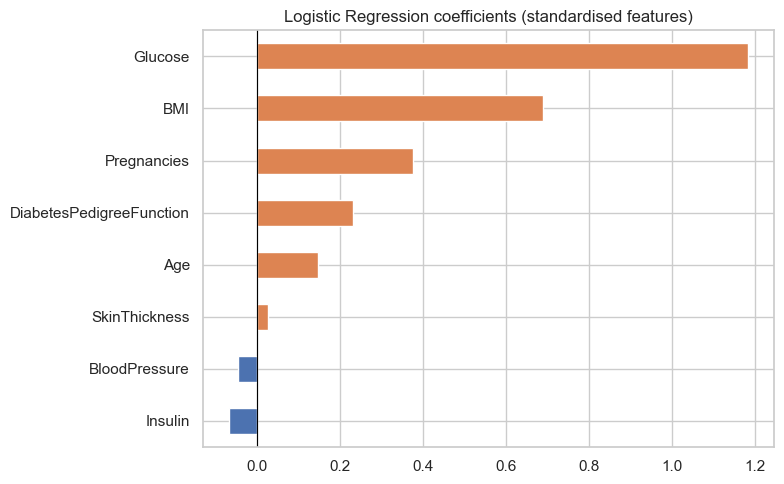

,coefficient,odds_ratio (per 1 SD)
Glucose,1.183,3.263
BMI,0.689,1.991
Pregnancies,0.377,1.459
DiabetesPedigreeFunction,0.233,1.263
Age,0.148,1.159
SkinThickness,0.028,1.029
BloodPressure,-0.044,0.957
Insulin,-0.066,0.936


In [21]:
coef = pd.DataFrame({
    "coefficient": model.coef_[0],
    "odds_ratio (per 1 SD)": np.exp(model.coef_[0]),
}, index=X.columns).sort_values("coefficient", ascending=False)

coef["coefficient"].plot(kind="barh", color=np.where(coef["coefficient"] > 0, "#DD8452", "#4C72B0"),
                         figsize=(8, 5))
plt.gca().invert_yaxis()
plt.axvline(0, color="black", lw=0.8)
plt.title("Logistic Regression coefficients (standardised features)")
plt.tight_layout(); plt.savefig(IMG_DIR / "feature_importance.png", dpi=120); plt.show()
coef.round(3)

## 4.2 ROC curve

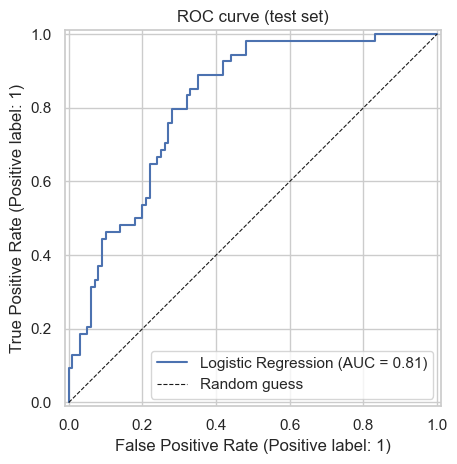

In [22]:
RocCurveDisplay.from_predictions(y_test, y_test_proba, name="Logistic Regression")
plt.plot([0, 1], [0, 1], "k--", lw=0.8, label="Random guess")
plt.legend(); plt.title("ROC curve (test set)")
plt.tight_layout(); plt.savefig(IMG_DIR / "roc_curve.png", dpi=120); plt.show()

The ROC-AUC measures how well the model **ranks** diabetic patients above non-diabetic ones across all thresholds (1.0 = perfect, 0.5 = random). A value above 0.8 means the predicted probabilities separate the two classes well, even if the default 0.5 cut-off is not ideal.

## 4.3 Improving recall: decision threshold trade-off
In a screening setting, **missing a diabetic patient (false negative) is usually more costly** than a false alarm, which only leads to a follow-up test. Because Logistic Regression outputs probabilities, we can lower the decision threshold to catch more positives and see what it costs in precision.

In [23]:
rows = []
for t in [0.5, 0.4, 0.35, 0.3]:
    pred = (y_test_proba >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, pred).ravel()
    rows.append({"threshold": t, **metrics(y_test, pred), "missed diabetics (FN)": fn_, "false alarms (FP)": fp_})
pd.DataFrame(rows).set_index("threshold").round(3)

,Accuracy,Precision,Recall,F1-score,missed diabetics (FN),false alarms (FP)
threshold,,,,,,
0.50,0.708,0.600,0.500,0.545,27,18
0.40,0.734,0.614,0.648,0.631,19,22
0.35,0.721,0.587,0.685,0.632,17,26
0.30,0.740,0.597,0.796,0.683,11,29


Lowering the threshold **raises recall** (fewer missed diabetic patients) at the cost of **lower precision** (more healthy patients flagged for follow-up). The right threshold is a business/clinical decision. Here, moving from 0.5 to 0.3 cuts missed diabetics from 27 to 11 while adding only 11 false alarms. For a screening tool, a lower threshold is usually preferred. Note that this threshold should be chosen on validation data. It is shown on the test set here only to illustrate the trade-off.

## 4.4 Conclusions & insights

**Model performance**
- Logistic Regression reaches **≈ 71% test accuracy** (≈ 79% in cross-validation) with an **ROC-AUC ≈ 0.81**, clearly better than the 65% majority-class baseline.
- The train/test gap (~9 points) is mostly due to the variance of a small test set. Cross-validation agrees with training accuracy, so the model is not heavily overfitting.
- It is better at identifying **non-diabetic** patients than diabetic ones. At the default threshold, **recall for diabetics is only 0.50**, which is the main limitation. Lowering the threshold to ~0.3 raises recall to ~0.80.

**Key risk factors (from the coefficients)**
- **Glucose** is by far the strongest predictor. Higher plasma glucose sharply increases the predicted risk, which matches clinical knowledge.
- **Glucose** odds ratio ≈ 3.3: each 1-SD increase (~30 mg/dL) roughly triples the odds of diabetes. **BMI** (≈ 2.0×), **Pregnancies** (≈ 1.5×), **DiabetesPedigreeFunction** (family history, ≈ 1.3×) and **Age** (≈ 1.2×) also increase risk.
- BloodPressure, SkinThickness and Insulin add little once the other features are known. Insulin and SkinThickness were also heavily imputed, which weakens their signal.

**Business / healthcare insights**
- The model is suitable as a **low-cost first-line screening aid**, not a diagnostic tool. It can prioritise which patients should get a confirmatory test (e.g. HbA1c).
- Focusing outreach on patients with **high glucose and high BMI**, especially with a family history, targets the highest-risk group.
- The decision threshold should be set based on the cost of a missed case vs a false alarm. For screening, a lower threshold improves recall.

**Limitations & next steps**
- Small dataset (768 patients) from a single population (Pima Indian women aged 21+), so results may not generalise to other groups.
- Heavy missingness in Insulin (~49%) and SkinThickness (~30%). Better imputation (e.g. KNN/iterative) could help.
- Possible improvements: `class_weight="balanced"`, threshold tuning on a validation set, and comparing tree-based models (Random Forest, Gradient Boosting).